In [1]:
import numpy as np
data = np.load('../tf_flowers_prepared.npz')

X_train = data['X_train']
y_train = data['y_train']

X_val = data['X_val']
y_val = data['y_val']

X_test = data['X_test']
y_test = data['y_test']

class_labels = data['class_names'].tolist()

In [34]:
from tensorflow.keras import layers, models

softmax_model = models.Sequential([
    layers.Input(shape=(150, 150, 3)),

    # Convertir chaque image en vecteur
    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    # Une seule couche de classification
    layers.Dropout(0.5),
    layers.Dense(3, activation='softmax')
])

softmax_model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_7 (Flatten)             │ (None, 67500)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 32)             │     2,160,032 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,160,611 (8.24 MB)

 Trainable params: 2,160,611 (8.24 MB)

 Non-trainable params: 0 (0.00 B)

In [35]:
softmax_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [36]:
import tensorflow as tf
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True,
    verbose=1
)

In [39]:
history_softmax = softmax_model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping]
)

Epoch 1/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.4102 - loss: 1.0500 - val_accuracy: 0.4167 - val_loss: 1.0724
Epoch 2/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.4074 - loss: 1.0489 - val_accuracy: 0.5028 - val_loss: 0.9972
Epoch 3/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.4481 - loss: 1.0171 - val_accuracy: 0.5417 - val_loss: 0.9416
Epoch 4/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.4676 - loss: 1.0206 - val_accuracy: 0.5167 - val_loss: 0.9941
Epoch 5/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.4463 - loss: 1.0340 - val_accuracy: 0.4722 - val_loss: 1.0300
Epoch 6/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.4269 - loss: 1.0472 - val_accuracy: 0.5167 - val_loss: 0.9894
Epoch 7/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.4546 - loss: 1.0057 - val_accuracy: 0.4278 - val_loss: 1.0404
Epoch 8/50
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.4278 - loss: 1.0164 - val_accuracy: 0.4583 - v

In [40]:
test_loss, test_accuracy = softmax_model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5083 - loss: 0.9564 
Test Accuracy: 0.5083333253860474
Test Loss: 0.9563974142074585


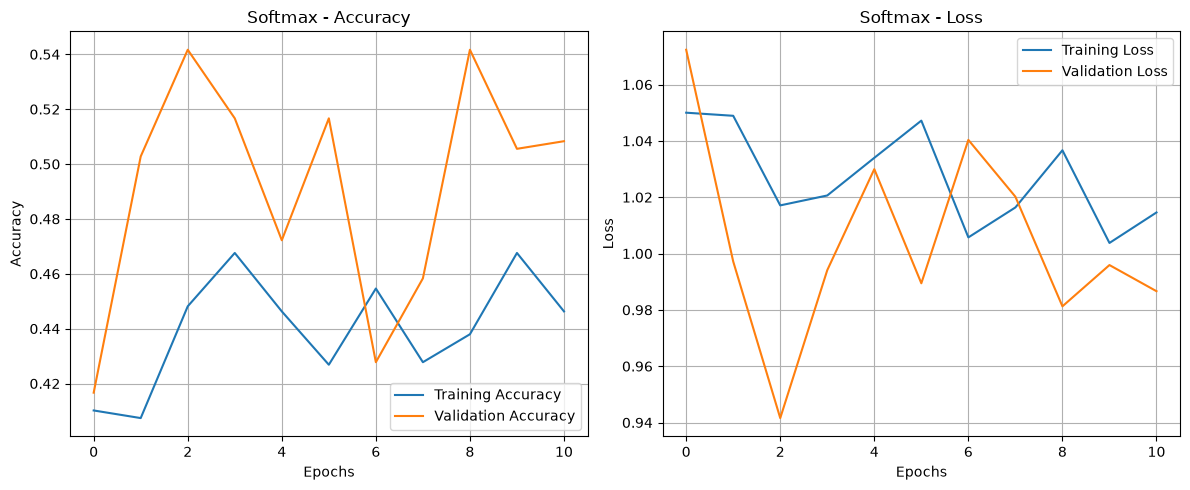

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_softmax.history['accuracy'], label='Training Accuracy')
plt.plot(history_softmax.history['val_accuracy'], label='Validation Accuracy')
plt.title('Softmax - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_softmax.history['loss'], label='Training Loss')
plt.plot(history_softmax.history['val_loss'], label='Validation Loss')
plt.title('Softmax - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Probabilités prédites
y_prob = softmax_model.predict(X_test)

# Classe avec la probabilité maximale
y_pred = np.argmax(y_prob, axis=1)

# Métriques
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, average='macro', zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred, average='macro', zero_division=0
))

print("F1-score:", f1_score(
    y_test, y_pred, average='macro', zero_division=0
))
class_names = ['daisy' ,  'roses', 'tulips']

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=class_names,
    zero_division=0
))

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
Accuracy: 0.5083333333333333
Precision: 0.4979099004961074
Recall: 0.5083333333333333
F1-score: 0.48610420689893247

Classification Report:
              precision    recall  f1-score   support

       daisy       0.54      0.82      0.65       120
       roses       0.60      0.44      0.51       120
      tulips       0.36      0.26      0.30       120

    accuracy                           0.51       360
   macro avg       0.50      0.51      0.49       360
weighted avg       0.50      0.51      0.49       360



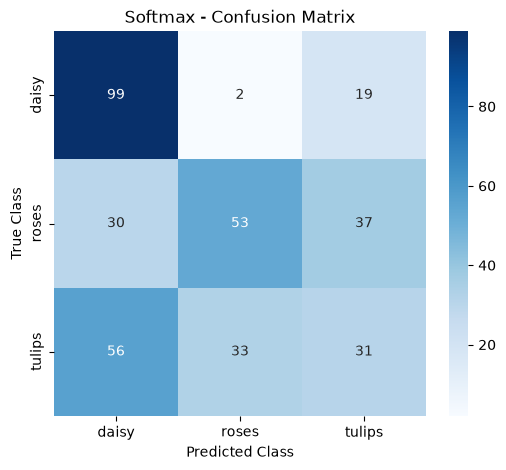

In [46]:
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Class')
plt.ylabel('True Class')
plt.title('Softmax - Confusion Matrix')
plt.show()